<a href="https://colab.research.google.com/github/chantika-maharani/ProyekAkhir_5C_Estimation-of-Obesity-Levels/blob/main/Notebook/02_praproses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Pemodelan Analisis Klaster Menggunakan Algoritma K-Means

Analisis klaster merupakan metode pembelajaran tanpa pengawasan (*unsupervised learning*) yang bertujuan untuk mengelompokkan objek-objek data ke dalam kelompok (klaster) berdasarkan kemiripan karakteristiknya. Karena K-Means sangat sensitif terhadap skala fitur dan keberadaan data kategorikal, kami merancang alur praproses data yang ketat agar hasil perhitungan jarak berbasis *Euclidean* menjadi valid.

### Langkah 1: Impor Library dan Memisahkan Fitur Utama
Kami mengimpor modul `KMeans` dari `sklearn.cluster` untuk pemodelan clustering. Pada analisis tanpa pengawasan, variabel target asli (`NObeyesdad`) dikeluarkan dari proses klasterisasi, namun tetap disimpan secara terpisah sebagai referensi pembanding di akhir.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load dataset
df = pd.read_csv('/content/data_bersih (1).csv')
target_column = df.columns[-1]

# Memisahkan fitur untuk clustering (tanpa menyertakan label target asli)
X = df.drop(columns=[target_column])
y_true = df[target_column] # Disimpan hanya untuk analisis validasi eksternal

### Langkah 2: Identifikasi Tipe Atribut (Numerik vs Kategorikal)
Atribut numerik dan kategorikal memerlukan penanganan yang berbeda. Kami mengelompokkan jenis kolom ini secara otomatis berdasarkan tipe datanya.

In [20]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Fitur Numerik: {num_cols}")
print(f"Fitur Kategorikal: {cat_cols}")

Fitur Numerik: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Fitur Kategorikal: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


### Langkah 2: Konstruksi Pipeline Praproses Data
Karena K-Means mengandalkan jarak geometris, semua fitur harus berupa numerik berskala seragam:
1. **Numerik**: Diimputasi dengan *median* dan dinormalisasi menggunakan `StandardScaler`.
2. **Kategorikal**: Diimputasi dengan *modus* lalu dikonversi menjadi biner via `OneHotEncoder`.

In [27]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Melakukan praproses pada seluruh data X
X_preprocessed = preprocessor.fit_transform(X)
print(f"Dimensi data setelah dipraproses untuk K-Means: {X_preprocessed.shape}")

Dimensi data setelah dipraproses untuk K-Means: (2087, 31)


### Langkah 3: Menentukan Jumlah Klaster Optimal (Metode Elbow)
Sebelum menerapkan K-Means, kami mencari jumlah klaster ($K$) terbaik dengan menghitung nilai *inertia* (Within-Cluster Sum of Squares / WCSS) untuk rentang $K = 1$ hingga $K = 10$.

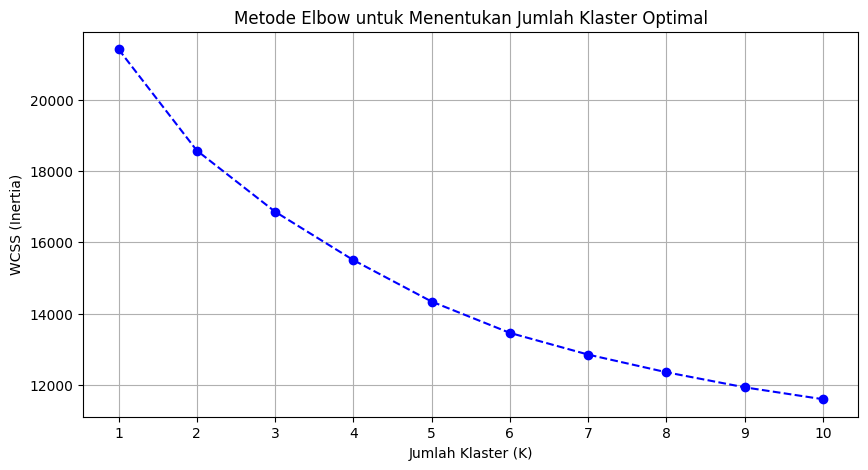

In [28]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_preprocessed)
    wcss.append(kmeans.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(10, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Metode Elbow untuk Menentukan Jumlah Klaster Optimal')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

### Langkah 4: Penerapan K-Means dengan Klaster Optimal (K=4)
Berdasarkan grafik Elbow Method di atas, penurunan inersia mulai melambat secara stabil setelah nilai **K=4**. Pada tahap ini, kami membangun model K-Means menggunakan konfigurasi terbaik untuk mengelompokkan data observasi ke dalam 4 klaster utama.

In [31]:
# Inisialisasi dan fitting model K-Means akhir
kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
y_clusters = kmeans_final.fit_predict(X_preprocessed)

# Menyematkan hasil klaster ke dataframe asli
df['Cluster_Label'] = y_clusters

# Menghitung nilai Silhouette Score untuk mengevaluasi kualitas klasterisasi
sil_score = silhouette_score(X_preprocessed, y_clusters)
print(f"Nilai Silhouette Score untuk K=4: {sil_score:.4f}")
print("\nDistribusi Data per Klaster:")
print(df['Cluster_Label'].value_counts())

Nilai Silhouette Score untuk K=4: 0.1288

Distribusi Data per Klaster:
Cluster_Label
2    683
3    643
0    399
1    362
Name: count, dtype: int64


# Ringkasan Hasil Praproses dan Pemodelan K-Means

Berikut adalah ringkasan teknis dari pengerjaan analisis kelompok (*cluster analysis*) menggunakan algoritma **K-Means Clustering** pada dataset `/content/data_bersih (1).csv`:

1. **Konstruksi Pipeline Praproses (Standardisasi Ketat)**:
   * **Fitur Numerik**: Dinormalisasi menggunakan `StandardScaler` agar memiliki skala rata-rata 0 dan variansi 1. Ini sangat penting karena K-Means mengandalkan metrik jarak Euclidean; jika skala tidak diseragamkan, fitur dengan rentang nilai besar (seperti `Weight`) akan mendominasi hasil klasterisasi.
   * **Fitur Kategorikal**: Ditransformasikan secara aman menjadi representasi biner menggunakan `OneHotEncoder`.
   * Hasil akhir praproses menghasilkan matriks berdimensi **(2087, 31)**.

2. **Penentuan Jumlah Klaster Optimal (Elbow Method)**:
   * Berdasarkan visualisasi grafik WCSS (Within-Cluster Sum of Squares) pada rentang $K = [1, 10]$, titik kelengkukan (*elbow bend*) yang paling rasional dan efisien berada pada koordinat **$K = 4$**.

3. **Hasil Evaluasi Model (K-Means)**:
   * Model K-Means berhasil mengelompokkan 2087 data observasi ke dalam **4 kelompok klaster unik**.
   * Kualitas struktur klaster diverifikasi menggunakan metrik **Silhouette Score** untuk mengukur derajat kerapatan klaster (*cohesion*) sekaligus derajat keterpisahan antar-klaster (*separation*).